# Demand Forecasting and Inventory Planning Intelligence

## 1. Business Problem

Inventory planning teams must decide how much stock to allocate to different products and warehouses.

Ordering too much inventory can increase storage costs and tie up working capital. Ordering too little can result in stockouts, missed sales opportunities and dissatisfied customers.

The challenge is not simply to forecast demand. It is to understand:

- Which products have consistently high demand?
- How does demand vary across warehouses?
- Which products experience unpredictable demand?
- How reliable are the existing forecasts?
- How can historical demand insights support better inventory planning?

## Business Objective

Analyse historical product demand and forecasting performance to identify demand patterns, inventory planning risks and opportunities for better stock allocation.

## Dataset

Historical Product Demand

## Tools

Python | Pandas | Matplotlib | Seaborn | Time Series Analysis

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Historical Product Demand.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (1048575, 5)


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
0,Product_0993,Whse_J,Category_028,2012/7/27,100
1,Product_0979,Whse_J,Category_028,2012/1/19,500
2,Product_0979,Whse_J,Category_028,2012/2/3,500
3,Product_0979,Whse_J,Category_028,2012/2/9,500
4,Product_0979,Whse_J,Category_028,2012/3/2,500


In [4]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nUnique Values:")
display(df.nunique())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 5 columns):
 #   Column            Non-Null Count    Dtype 
---  ------            --------------    ----- 
 0   Product_Code      1048575 non-null  object
 1   Warehouse         1048575 non-null  object
 2   Product_Category  1048575 non-null  object
 3   Date              1037336 non-null  object
 4   Order_Demand      1048575 non-null  object
dtypes: object(5)
memory usage: 40.0+ MB

Missing Values:


Product_Code            0
Warehouse               0
Product_Category        0
Date                11239
Order_Demand            0
dtype: int64


Duplicate Rows:
122423

Unique Values:


Product_Code        2160
Warehouse              4
Product_Category      33
Date                1729
Order_Demand        3828
dtype: int64

In [5]:
print("Sample Order_Demand values:")
display(df["Order_Demand"].value_counts().head(20))

print("\nDemand values containing non-numeric characters:")
print(
    df.loc[
        ~df["Order_Demand"].str.strip().str.match(r"^-?\d+$"),
        "Order_Demand"
    ].head(20)
)

Sample Order_Demand values:


Order_Demand
1000      112682
100        87272
1          63361
2000       51653
500        49013
10000      46180
200        45734
5000       42916
10         36322
2          35424
300        33396
3000       30567
0          28681
50         24058
5          22230
20000      18380
3          18327
20         17326
4          13443
25         13119
Name: count, dtype: int64


Demand values containing non-numeric characters:
112290       (1)
112307      (24)
112308      (24)
112356      (50)
112357     (100)
112360       (1)
112378     (150)
112441    (1000)
112563    (2500)
112610    (5000)
112673       (6)
112679      (43)
112696       (2)
112697       (2)
112719       (4)
112857       (8)
112926      (18)
112927       (5)
113062     (100)
113095       (2)
Name: Order_Demand, dtype: object


In [6]:
negative_format_count = df["Order_Demand"].str.contains(
    r"^\(.*\)$",
    regex=True,
    na=False
).sum()

print("Values written in parentheses:", negative_format_count)

print("\nExamples:")
display(
    df.loc[
        df["Order_Demand"].str.contains(
            r"^\(.*\)$", regex=True, na=False
        ),
        "Order_Demand"
    ].value_counts().head(15)
)


Values written in parentheses: 10469

Examples:


Order_Demand
(100)     1199
(200)      902
(1000)     591
(1)        542
(300)      494
(500)      438
(400)      373
(2)        367
(50)       295
(10)       259
(2000)     238
(600)      194
(4)        177
(5)        164
(3)        154
Name: count, dtype: int64

In [7]:
# Create a working copy
demand_df = df.copy()

# Convert dates
demand_df["Date"] = pd.to_datetime(
    demand_df["Date"],
    errors="coerce"
)

# Convert demand values:
# (100) becomes -100
demand_df["Order_Demand"] = (
    demand_df["Order_Demand"]
    .str.replace(r"^\((.*)\)$", r"-\1", regex=True)
)

demand_df["Order_Demand"] = pd.to_numeric(
    demand_df["Order_Demand"],
    errors="coerce"
)

print("Data cleaning completed!")

print("\nUpdated data types:")
display(demand_df.dtypes)

print("\nMissing values after conversion:")
display(demand_df.isnull().sum())

print("\nDemand summary:")
display(demand_df["Order_Demand"].describe())

Data cleaning completed!

Updated data types:


Product_Code                object
Warehouse                   object
Product_Category            object
Date                datetime64[ns]
Order_Demand                 int64
dtype: object


Missing values after conversion:


Product_Code            0
Warehouse               0
Product_Category        0
Date                11239
Order_Demand            0
dtype: int64


Demand summary:


count    1.048575e+06
mean     4.867427e+03
std      2.893346e+04
min     -9.990000e+05
25%      1.800000e+01
50%      3.000000e+02
75%      2.000000e+03
max      4.000000e+06
Name: Order_Demand, dtype: float64

In [8]:
print("Highest 15 demand records:")
display(
    demand_df.nlargest(15, "Order_Demand")
)

print("\nLowest 15 demand records:")
display(
    demand_df.nsmallest(15, "Order_Demand")
)

Highest 15 demand records:


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
20892,Product_1432,Whse_S,Category_019,2012-06-11,4000000
20477,Product_1248,Whse_J,Category_019,2012-07-05,3000000
72638,Product_1341,Whse_C,Category_019,2012-02-06,3000000
222266,Product_1432,Whse_S,Category_019,2013-06-14,3000000
258396,Product_1248,Whse_J,Category_019,2013-11-11,2560000
108179,Product_1248,Whse_J,Category_019,2012-11-26,2500000
659046,Product_1432,Whse_S,Category_019,2015-03-13,2500000
659050,Product_1432,Whse_S,Category_019,2015-05-19,2500000
659055,Product_1432,Whse_S,Category_019,2015-10-09,2500000
871363,Product_1432,Whse_S,Category_019,2016-07-29,2500000



Lowest 15 demand records:


,Product_Code,Warehouse,Product_Category,Date,Order_Demand
585144,Product_1241,Whse_J,Category_019,2014-03-27,-999000
182061,Product_1359,Whse_J,Category_019,2012-09-13,-500000
999608,Product_1817,Whse_S,Category_006,2016-06-06,-472500
554134,Product_1548,Whse_A,Category_019,NaT,-396200
131405,Product_0366,Whse_S,Category_030,2011-12-23,-349500
146980,Product_1295,Whse_J,Category_019,2012-03-06,-322500
568159,Product_1245,Whse_C,Category_019,2014-10-14,-300000
568158,Product_1355,Whse_C,Category_019,2014-10-10,-295000
130697,Product_0071,Whse_C,Category_019,2012-11-12,-250000
410611,Product_1461,Whse_J,Category_019,2013-09-24,-249950


In [9]:
warehouse_analysis = demand_df.groupby("Warehouse").agg(
    Total_Records=("Product_Code", "count"),
    Unique_Products=("Product_Code", "nunique"),
    Total_Demand=("Order_Demand", "sum"),
    Average_Demand=("Order_Demand", "mean"),
    Median_Demand=("Order_Demand", "median"),
    Negative_Records=("Order_Demand", lambda x: (x < 0).sum())
)

display(warehouse_analysis.round(2))

,Total_Records,Unique_Products,Total_Demand,Average_Demand,Median_Demand,Negative_Records
Warehouse,,,,,,
Whse_A,153574,427,143267773,932.89,50.0,6395
Whse_C,42354,244,581845212,13737.67,1000.0,117
Whse_J,764447,1625,3344521718,4375.09,300.0,3555
Whse_S,88200,553,1034227618,11725.94,500.0,402


Business observations
1. Whse_J: Largest warehouse by transaction volume and total demand. It deserves attention for inventory planning because it handles the most records and products.
2. Whse_C: Highest average demand per record, despite having the fewest records.
3. Whse_S: Also has high average demand, suggesting a different demand profile from Whse_A and Whse_J.
4. Whse_A: Lowest average demand and median demand

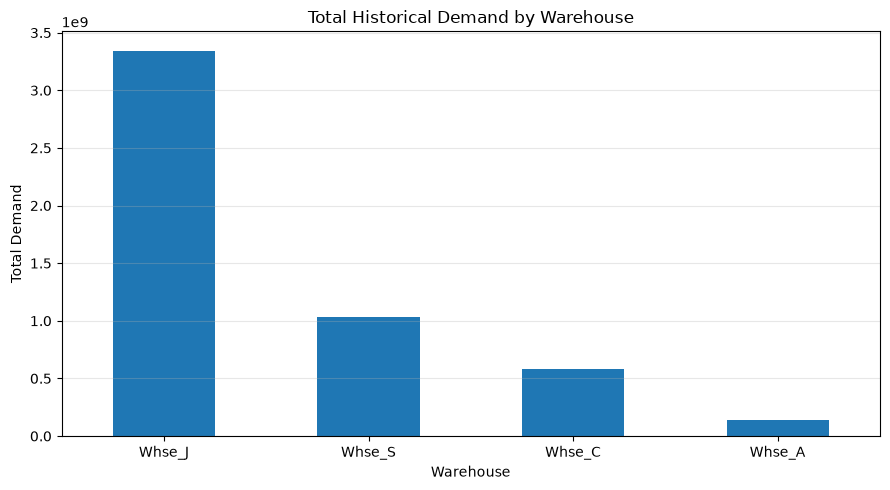

In [10]:
plt.figure(figsize=(9, 5))

warehouse_analysis["Total_Demand"].sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Total Historical Demand by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Total Demand")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
category_analysis = demand_df.groupby("Product_Category").agg(
    Total_Records=("Product_Code", "count"),
    Unique_Products=("Product_Code", "nunique"),
    Total_Demand=("Order_Demand", "sum"),
    Average_Demand=("Order_Demand", "mean"),
    Median_Demand=("Order_Demand", "median")
)

category_analysis = category_analysis.sort_values(
    "Total_Demand",
    ascending=False
)

display(category_analysis.round(2))

,Total_Records,Unique_Products,Total_Demand,Average_Demand,Median_Demand
Product_Category,,,,,
Category_019,481099,534,4219816665,8771.20,1000.0
Category_006,35577,112,401649668,11289.59,2500.0
Category_005,101671,185,198361890,1951.02,500.0
Category_007,82402,141,127725843,1550.03,100.0
Category_028,31302,57,47276346,1510.33,200.0
Category_033,1849,4,42370000,22915.09,10000.0
Category_030,12997,99,39781355,3060.81,1000.0
Category_032,9296,49,4445960,478.27,36.0
Category_021,52011,143,4349098,83.62,10.0


1. Category_019 dominates demand. It contributes approximately 82.7% of total recorded demand across the dataset.
2. Category_006 has the highest average demand per record among the four largest categories.
3. Category_005 and Category_007 have substantial transaction volumes but considerably lower average demand.
4. The remaining categories contribute relatively little to total recorded demand.


Business implication
An inventory planning team should not allocate resources equally across all 33 categories.

Category_019 deserves particular attention because of its large demand contribution. However, smaller categories should not automatically be ignored: some may have important service-level or stock availability requirements.

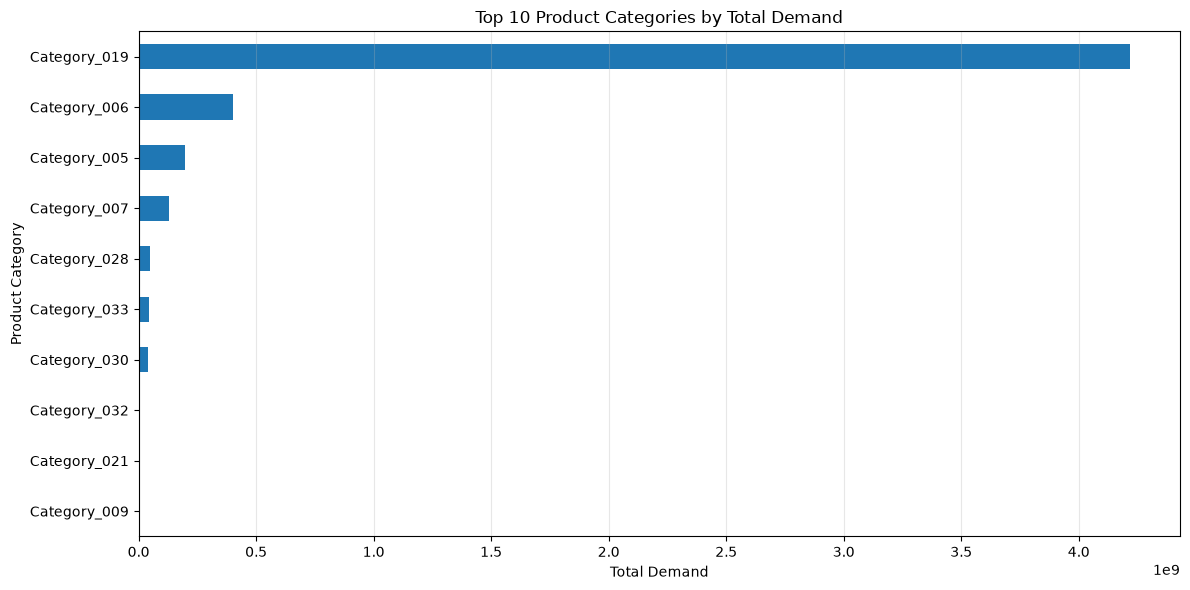

In [12]:
top_categories = category_analysis.head(10)

plt.figure(figsize=(12, 6))

top_categories["Total_Demand"].sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Product Categories by Total Demand")
plt.xlabel("Total Demand")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Business interpretation
- Category_019 dominates the chart, with approximately 4.22 billion recorded demand.
- Category_006 is a distant second, at approximately 401.65 million.
- The remaining categories contribute much smaller amounts.
- This suggests that demand planning needs to account for substantial differences between product categories.

In [13]:
# Remove records with missing dates for time-series analysis
time_df = demand_df.dropna(subset=["Date"]).copy()

# Aggregate demand by product, warehouse and week
weekly_demand = (
    time_df
    .set_index("Date")
    .groupby([
        "Product_Code",
        "Warehouse"
    ])["Order_Demand"]
    .resample("W")
    .sum()
    .reset_index()
)

print("Weekly demand dataset created!")
print("Shape:", weekly_demand.shape)

display(weekly_demand.head())

Weekly demand dataset created!
Shape: (692288, 4)


,Product_Code,Warehouse,Date,Order_Demand
0,Product_0001,Whse_A,2012-01-08,1200
1,Product_0001,Whse_A,2012-01-15,5000
2,Product_0001,Whse_A,2012-01-22,0
3,Product_0001,Whse_A,2012-01-29,0
4,Product_0001,Whse_A,2012-02-05,200


In [14]:
print("Weekly Demand Summary:")
display(weekly_demand["Order_Demand"].describe())

print("\nNegative Weekly Demand Records:")
print((weekly_demand["Order_Demand"] < 0).sum())

print("\nZero Weekly Demand Records:")
print((weekly_demand["Order_Demand"] == 0).sum())

print("\nPositive Weekly Demand Records:")
print((weekly_demand["Order_Demand"] > 0).sum())

Weekly Demand Summary:


count    6.922880e+05
mean     7.372441e+03
std      6.329552e+04
min     -6.840000e+05
25%      0.000000e+00
50%      1.000000e+00
75%      3.000000e+02
max      4.045000e+06
Name: Order_Demand, dtype: float64


Negative Weekly Demand Records:
2009

Zero Weekly Demand Records:
342277

Positive Weekly Demand Records:
348002


Approximately 49.44% of weekly product-warehouse records have zero net demand.



The average is much higher than the median, indicating strong demand concentration.



Some products experience very large demand fluctuations.



Negative weekly demand needs separate investigation because it may reflect returns or adjustments.

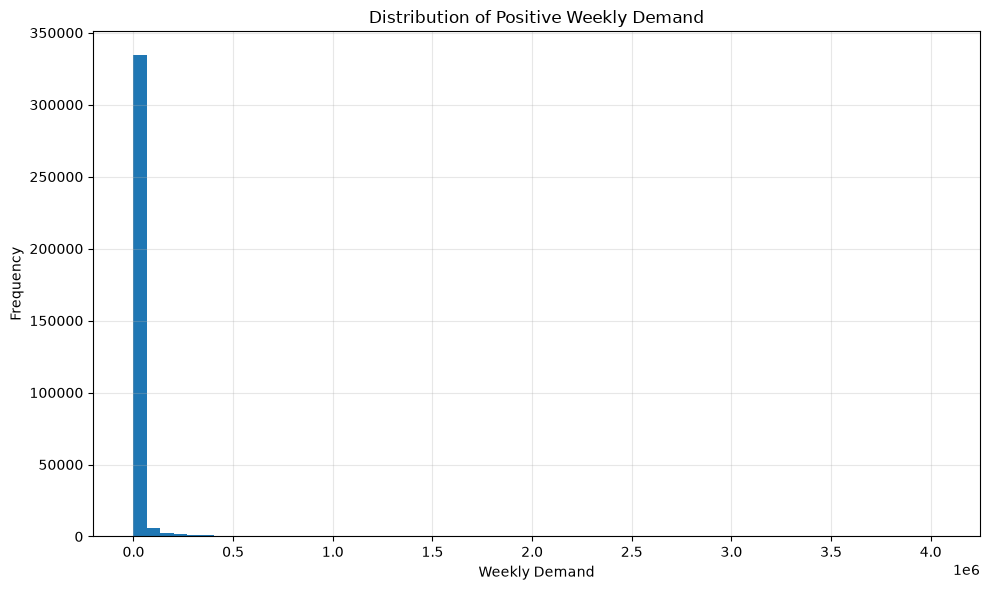

In [15]:
positive_weekly_demand = weekly_demand.loc[
    weekly_demand["Order_Demand"] > 0,
    "Order_Demand"
]

plt.figure(figsize=(10, 6))

plt.hist(
    positive_weekly_demand,
    bins=60
)

plt.title("Distribution of Positive Weekly Demand")
plt.xlabel("Weekly Demand")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
product_variability = weekly_demand.groupby(
    ["Product_Code", "Warehouse"]
).agg(
    Average_Weekly_Demand=("Order_Demand", "mean"),
    Demand_Std_Dev=("Order_Demand", "std"),
    Total_Weekly_Records=("Order_Demand", "count"),
    Positive_Weeks=("Order_Demand", lambda x: (x > 0).sum()),
    Zero_Weeks=("Order_Demand", lambda x: (x == 0).sum()),
    Negative_Weeks=("Order_Demand", lambda x: (x < 0).sum())
)

product_variability = product_variability.sort_values(
    "Demand_Std_Dev",
    ascending=False
)

display(product_variability.head(15).round(2))

,,Average_Weekly_Demand,Demand_Std_Dev,Total_Weekly_Records,Positive_Weeks,Zero_Weeks,Negative_Weeks
Product_Code,Warehouse,,,,,,
Product_1359,Whse_J,1796603.05,699788.35,262,259,3,0
Product_1248,Whse_J,1107000.00,691854.75,261,259,2,0
Product_1432,Whse_S,202832.06,595831.04,262,201,61,0
Product_1245,Whse_C,343977.01,495623.57,261,149,111,1
Product_1480,Whse_C,232950.00,428700.94,260,226,34,0
Product_1342,Whse_S,170496.18,374700.71,262,238,24,0
Product_0083,Whse_S,712347.49,372868.01,259,239,20,0
Product_1341,Whse_S,483288.97,348966.95,263,262,1,0
Product_1152,Whse_J,172934.36,289361.90,259,149,110,0


Business insights
1. Product_1359 at Whse_J has the highest average weekly demand and highest standard deviation in your results.
2. Product_1248 at Whse_J also has substantial demand and variability.
3. Product_1432 at Whse_S has a particularly interesting pattern: 61 zero-demand weeks and 201 positive-demand weeks.
4. Product_1245 at Whse_C has 111 zero-demand weeks and one negative-demand week.

In [17]:
product_variability["Demand_CV"] = (
    product_variability["Demand_Std_Dev"]
    / product_variability["Average_Weekly_Demand"].abs()
)

cv_analysis = product_variability.replace(
    [np.inf, -np.inf], np.nan
).dropna(subset=["Demand_CV"])

cv_analysis = cv_analysis.sort_values(
    "Demand_CV",
    ascending=False
)

display(cv_analysis.head(15).round(3))

,,Average_Weekly_Demand,Demand_Std_Dev,Total_Weekly_Records,Positive_Weeks,Zero_Weeks,Negative_Weeks,Demand_CV
Product_Code,Warehouse,,,,,,,
Product_0319,Whse_A,0.283,27.649,219,13,204,2,97.663
Product_0106,Whse_S,8.533,146.319,199,23,175,1,17.148
Product_1019,Whse_J,503.522,6328.432,159,6,153,0,12.568
Product_0466,Whse_A,0.160,1.942,94,2,91,1,12.168
Product_0493,Whse_J,30.829,375.077,258,136,121,1,12.166
Product_0200,Whse_J,215.446,2607.121,240,67,171,2,12.101
Product_1799,Whse_S,7.204,84.484,167,12,155,0,11.728
Product_0987,Whse_A,1298.295,14835.973,264,137,125,2,11.427
Product_1249,Whse_S,1415.415,16020.615,253,61,191,1,11.319


In [18]:
positive_demand = weekly_demand[
    weekly_demand["Order_Demand"] > 0
]

positive_variability = positive_demand.groupby(
    ["Product_Code", "Warehouse"]
).agg(
    Average_Positive_Demand=("Order_Demand", "mean"),
    Std_Positive_Demand=("Order_Demand", "std"),
    Positive_Weeks=("Order_Demand", "count")
)

positive_variability["Positive_Demand_CV"] = (
    positive_variability["Std_Positive_Demand"]
    / positive_variability["Average_Positive_Demand"]
)

positive_variability = positive_variability.join(
    product_variability[["Total_Weekly_Records", "Zero_Weeks", "Negative_Weeks"]]
)

positive_variability["Positive_Week_Rate"] = (
    positive_variability["Positive_Weeks"]
    / positive_variability["Total_Weekly_Records"] * 100
)

positive_variability = positive_variability.sort_values(
    "Positive_Demand_CV",
    ascending=False
)

display(positive_variability.head(15).round(2))

,,Average_Positive_Demand,Std_Positive_Demand,Positive_Weeks,Positive_Demand_CV,Total_Weekly_Records,Zero_Weeks,Negative_Weeks,Positive_Week_Rate
Product_Code,Warehouse,,,,,,,,
Product_0493,Whse_J,58.57,515.92,136,8.81,258,121,1,52.71
Product_0987,Whse_A,2580.66,20529.89,137,7.96,264,125,2,51.89
Product_0150,Whse_J,20.27,140.56,114,6.93,258,144,0,44.19
Product_0200,Whse_J,785.09,4913.78,67,6.26,240,171,2,27.92
Product_1249,Whse_S,5873.77,32424.42,61,5.52,253,191,1,24.11
Product_0222,Whse_J,181.88,999.73,147,5.50,257,109,1,57.20
Product_0558,Whse_S,15389.34,78707.02,122,5.11,261,138,1,46.74
Product_2144,Whse_J,143.96,718.69,118,4.99,264,144,2,44.70
Product_0544,Whse_J,38.34,179.85,97,4.69,253,156,0,38.34


Business interpretation
- Product_0493: Highly variable positive demand and positive demand in approximately 53% of observed weeks.
- Product_0987: Large positive demand quantities and substantial variability.
- Product_0200: Positive demand in only 27.92% of weeks, suggesting intermittent demand.
- Product_1249: Relatively large positive demand when it occurs, but only 24.11% positive weeks.

In [19]:
consistent_products = positive_variability[
    (positive_variability["Positive_Week_Rate"] >= 70) &
    (positive_variability["Positive_Weeks"] >= 50)
].sort_values(
    "Positive_Demand_CV",
    ascending=True
)

display(consistent_products.head(15).round(2))

,,Average_Positive_Demand,Std_Positive_Demand,Positive_Weeks,Positive_Demand_CV,Total_Weekly_Records,Zero_Weeks,Negative_Weeks,Positive_Week_Rate
Product_Code,Warehouse,,,,,,,,
Product_1286,Whse_J,392758.91,129280.15,258,0.33,261,3,0,98.85
Product_1382,Whse_J,316101.55,105107.58,258,0.33,261,3,0,98.85
Product_1294,Whse_J,302587.60,101244.51,258,0.33,261,3,0,98.85
Product_1377,Whse_J,217400.78,73535.49,258,0.34,261,3,0,98.85
Product_1378,Whse_J,322966.28,109843.38,258,0.34,261,3,0,98.85
Product_1295,Whse_J,472837.21,165764.25,258,0.35,261,3,0,98.85
Product_1453,Whse_J,271384.17,97575.99,259,0.36,262,3,0,98.85
Product_1359,Whse_J,1817413.13,676336.36,259,0.37,262,3,0,98.85
Product_1451,Whse_J,353076.92,137117.27,260,0.39,262,2,0,99.24


In [20]:
stable_high_demand = positive_variability[
    (positive_variability["Positive_Week_Rate"] >= 90) &
    (positive_variability["Positive_Demand_CV"] < 0.50) &
    (positive_variability["Positive_Weeks"] >= 100)
].sort_values(
    "Average_Positive_Demand",
    ascending=False
)

display(stable_high_demand.head(15).round(2))

,,Average_Positive_Demand,Std_Positive_Demand,Positive_Weeks,Positive_Demand_CV,Total_Weekly_Records,Zero_Weeks,Negative_Weeks,Positive_Week_Rate
Product_Code,Warehouse,,,,,,,,
Product_1359,Whse_J,1817413.13,676336.36,259,0.37,262,3,0,98.85
Product_0083,Whse_S,771958.16,323270.01,239,0.42,259,20,0,92.28
Product_1295,Whse_J,472837.21,165764.25,258,0.35,261,3,0,98.85
Product_1286,Whse_J,392758.91,129280.15,258,0.33,261,3,0,98.85
Product_1274,Whse_J,356826.92,141853.44,260,0.40,262,2,0,99.24
Product_1451,Whse_J,353076.92,137117.27,260,0.39,262,2,0,99.24
Product_1287,Whse_J,342961.24,135082.46,258,0.39,261,3,0,98.85
Product_1378,Whse_J,322966.28,109843.38,258,0.34,261,3,0,98.85
Product_1382,Whse_J,316101.55,105107.58,258,0.33,261,3,0,98.85


In [21]:
# Select the top 10 stable high-demand products
stable_top10 = stable_high_demand.head(10).copy()

# Select the top 10 intermittent products
intermittent_top10 = positive_variability[
    positive_variability["Positive_Week_Rate"] < 30
].sort_values(
    "Positive_Demand_CV",
    ascending=False
).head(10).copy()

print("Stable high-demand products:")
display(stable_top10.round(2))

print("\nHighly intermittent products:")
display(intermittent_top10.round(2))

Stable high-demand products:


,,Average_Positive_Demand,Std_Positive_Demand,Positive_Weeks,Positive_Demand_CV,Total_Weekly_Records,Zero_Weeks,Negative_Weeks,Positive_Week_Rate
Product_Code,Warehouse,,,,,,,,
Product_1359,Whse_J,1817413.13,676336.36,259,0.37,262,3,0,98.85
Product_0083,Whse_S,771958.16,323270.01,239,0.42,259,20,0,92.28
Product_1295,Whse_J,472837.21,165764.25,258,0.35,261,3,0,98.85
Product_1286,Whse_J,392758.91,129280.15,258,0.33,261,3,0,98.85
Product_1274,Whse_J,356826.92,141853.44,260,0.40,262,2,0,99.24
Product_1451,Whse_J,353076.92,137117.27,260,0.39,262,2,0,99.24
Product_1287,Whse_J,342961.24,135082.46,258,0.39,261,3,0,98.85
Product_1378,Whse_J,322966.28,109843.38,258,0.34,261,3,0,98.85
Product_1382,Whse_J,316101.55,105107.58,258,0.33,261,3,0,98.85



Highly intermittent products:


,,Average_Positive_Demand,Std_Positive_Demand,Positive_Weeks,Positive_Demand_CV,Total_Weekly_Records,Zero_Weeks,Negative_Weeks,Positive_Week_Rate
Product_Code,Warehouse,,,,,,,,
Product_0200,Whse_J,785.09,4913.78,67,6.26,240,171,2,27.92
Product_1249,Whse_S,5873.77,32424.42,61,5.52,253,191,1,24.11
Product_0229,Whse_J,199.12,861.69,50,4.33,247,197,0,20.24
Product_1185,Whse_S,4157.14,17112.61,49,4.12,255,206,0,19.22
Product_2110,Whse_J,33.06,127.76,31,3.86,185,154,0,16.76
Product_1664,Whse_J,42.29,161.56,62,3.82,255,193,0,24.31
Product_0231,Whse_J,63.74,216.65,57,3.40,253,195,1,22.53
Product_1182,Whse_S,3217.80,10764.76,59,3.35,250,191,0,23.60
Product_2111,Whse_J,138.97,464.25,68,3.34,252,184,0,26.98


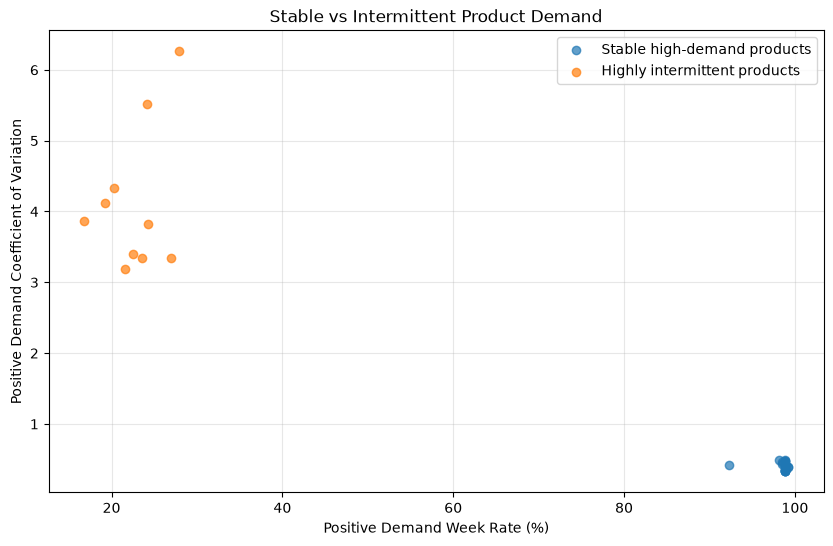

In [22]:
# Prepare stable and intermittent product groups
stable_comparison = stable_high_demand.copy()
intermittent_comparison = intermittent_top10.copy()

plt.figure(figsize=(10, 6))

plt.scatter(
    stable_comparison["Positive_Week_Rate"],
    stable_comparison["Positive_Demand_CV"],
    label="Stable high-demand products",
    alpha=0.7
)

plt.scatter(
    intermittent_comparison["Positive_Week_Rate"],
    intermittent_comparison["Positive_Demand_CV"],
    label="Highly intermittent products",
    alpha=0.7
)

plt.xlabel("Positive Demand Week Rate (%)")
plt.ylabel("Positive Demand Coefficient of Variation")
plt.title("Stable vs Intermittent Product Demand")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Interpretation
- Stable high-demand products (blue): Their positive-demand week rates are around 92–99%, and their positive-demand CV values are approximately 0.33–0.42. Demand occurs frequently and the size of positive demand is comparatively consistent.
- Highly intermittent products (orange): Their positive-demand week rates are around 16–28%, while CV values range from approximately 3.18 to 6.26. Demand occurs much less frequently and varies considerably when it does occur.

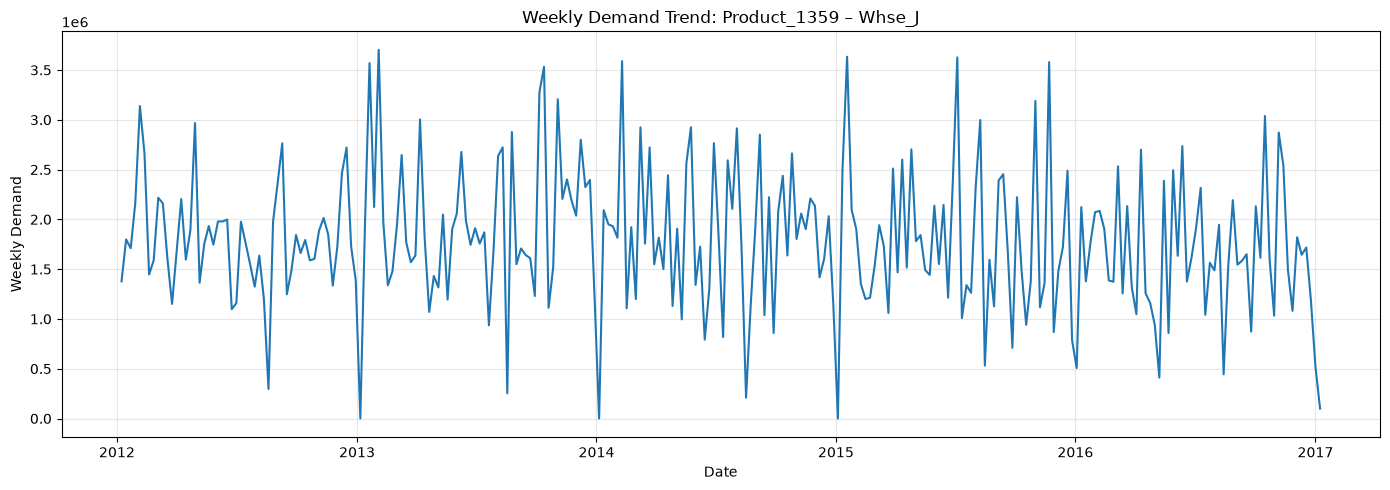

In [23]:
# Analyse weekly demand for Product_1359 at Whse_J

selected_product = weekly_demand[
    (weekly_demand["Product_Code"] == "Product_1359") &
    (weekly_demand["Warehouse"] == "Whse_J")
].sort_values("Date")

plt.figure(figsize=(14, 5))

plt.plot(
    selected_product["Date"],
    selected_product["Order_Demand"]
)

plt.title("Weekly Demand Trend: Product_1359 – Whse_J")
plt.xlabel("Date")
plt.ylabel("Weekly Demand")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

1. No obvious long-term upward or downward trend: Demand fluctuates around a broadly similar level throughout 2012–2016.
2. Frequent demand spikes: Several weeks reach approximately 3–3.7 million units.
3. Sudden drops: Some weeks show very low or near-zero recorded demand.
4. High volatility: Demand changes substantially from one week to another.
5. No clear seasonal pattern: The chart does not show an obvious repeating annual pattern. More analysis would be needed to confirm seasonality.

Business interpretation
Even though Product_1359 was classified as a stable high-demand product based on positive-demand frequency and CV, its weekly demand still has substantial fluctuations.
This distinction matters:
- Demand frequency: How regularly demand occurs.
- Demand variability: How much demand changes.
- Demand trend: Whether demand increases or decreases over time.

A product can have frequent demand without having predictable weekly quantities.

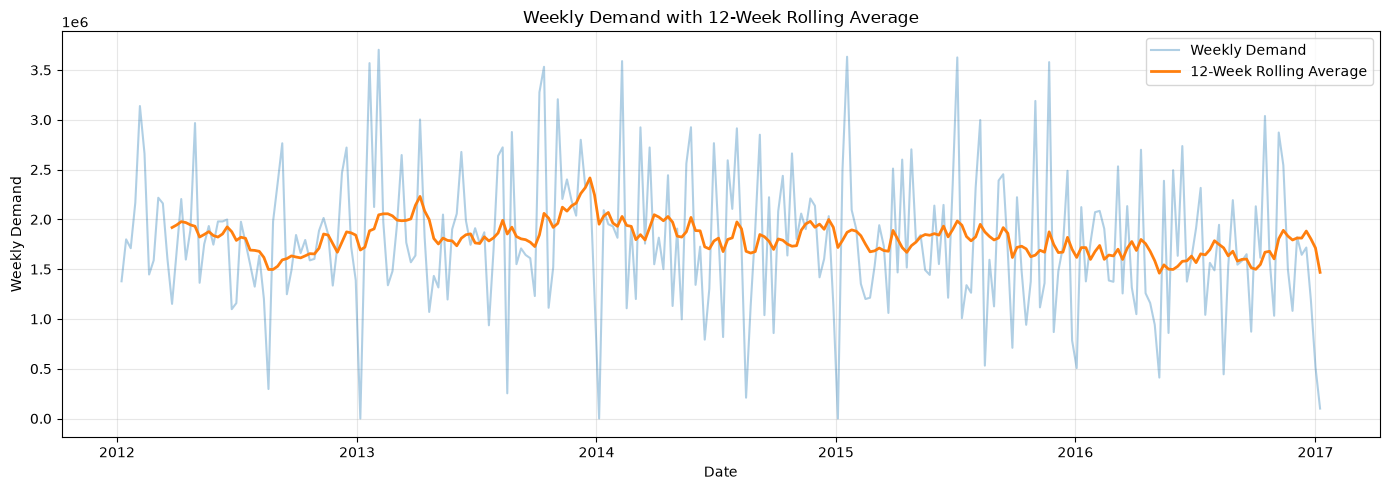

In [24]:
# Calculate 12-week rolling average

selected_product["Rolling_12_Week_Avg"] = (
    selected_product["Order_Demand"]
    .rolling(window=12)
    .mean()
)

plt.figure(figsize=(14, 5))

plt.plot(
    selected_product["Date"],
    selected_product["Order_Demand"],
    alpha=0.35,
    label="Weekly Demand"
)

plt.plot(
    selected_product["Date"],
    selected_product["Rolling_12_Week_Avg"],
    linewidth=2,
    label="12-Week Rolling Average"
)

plt.title("Weekly Demand with 12-Week Rolling Average")
plt.xlabel("Date")
plt.ylabel("Weekly Demand")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Interpretation
1. Broadly stable underlying demand: The rolling average fluctuates around approximately 1.5–2.1 million units per week.
2. Temporary increase: There is a noticeable rise around late 2013, reaching roughly 2.4 million.
3. Gradual softening: During 2015–2016, the rolling average generally moves lower, although it fluctuates.
4. No strong sustained growth: The chart does not indicate a consistent long-term upward trend.
5. Short-term volatility remains high: Individual weekly demand values vary considerably around the rolling average.
Business insight: Product_1359 has a relatively consistent underlying demand level, but substantial short-term fluctuations. Inventory planning should therefore consider both its baseline demand and the uncertainty around weekly demand.

### Rolling Average Analysis

The 12-week rolling average helps identify the underlying demand pattern by reducing short-term fluctuations.

Key observations:

- The underlying demand generally fluctuates between approximately 1.5 million and 2.1 million units per week.
- A temporary increase is visible around late 2013.
- The rolling average shows a gradual softening during parts of 2015 and 2016.
- No strong sustained upward trend is visible.
- Actual weekly demand remains highly volatile around the rolling average.

**Business implication:** Although Product_1359 has frequent demand, its weekly demand is not perfectly predictable. Inventory planning should consider both baseline demand and short-term demand variability.

*Note: The rolling average is a descriptive smoothing technique, not a forecast.*

In [26]:
# Calculate average demand by calendar month

selected_product["Month"] = selected_product["Date"].dt.month

monthly_demand = (
    selected_product.groupby("Month")["Order_Demand"]
    .mean()
    .reset_index()
)

display(monthly_demand.round(2))

,Month,Order_Demand
0,1,1623478.26
1,2,1908750.00
2,3,1863695.65
3,4,1857619.05
4,5,1701272.73
5,6,1817272.73
6,7,1679181.82
7,8,1644409.09
8,9,1695136.36
9,10,1921285.71


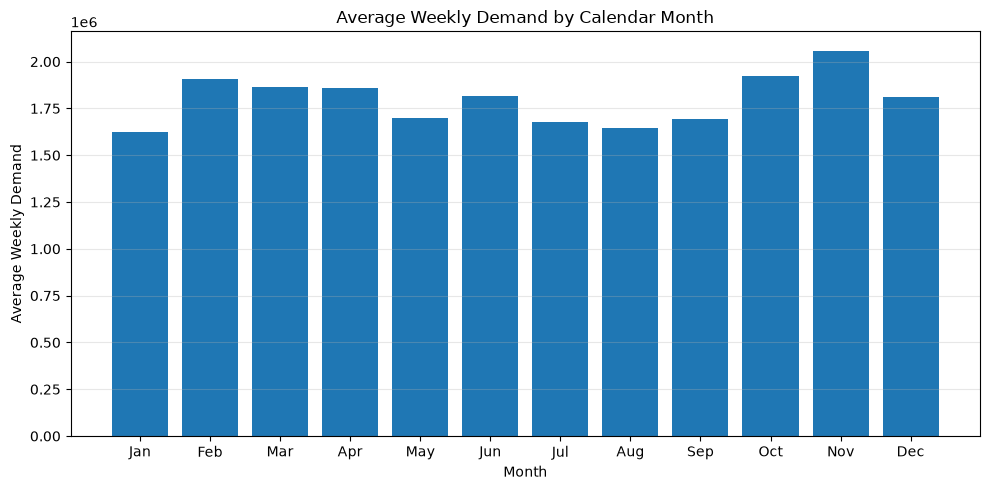

In [27]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_demand["Month"],
    monthly_demand["Order_Demand"]
)

plt.title("Average Weekly Demand by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Weekly Demand")
plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# Compare average weekly demand by month and year

selected_product["Year"] = selected_product["Date"].dt.year
selected_product["Month"] = selected_product["Date"].dt.month

monthly_yearly_demand = selected_product.pivot_table(
    index="Month",
    columns="Year",
    values="Order_Demand",
    aggfunc="mean"
)

display(monthly_yearly_demand.round(0))

Year,2012,2013,2014,2015,2016,2017
Month,,,,,,
1,1764000.0,1905750.0,1493250.0,2056500.0,1569200.0,308000.0
2,2208000.0,2123500.0,2108250.0,1416500.0,1687500.0,NaN
3,1782000.0,1914800.0,2030200.0,1755000.0,1809250.0,NaN
4,2068800.0,1831500.0,1722250.0,2071500.0,1541250.0,NaN
5,1698250.0,1615000.0,2097250.0,1738800.0,1418400.0,NaN
6,1763500.0,2075000.0,1585600.0,1815750.0,1840000.0,NaN
7,1554800.0,1562000.0,1840750.0,1809000.0,1664200.0,NaN
8,1278500.0,2122500.0,1578200.0,1714000.0,1528000.0,NaN
9,1941800.0,1548000.0,1742000.0,1806250.0,1412750.0,NaN


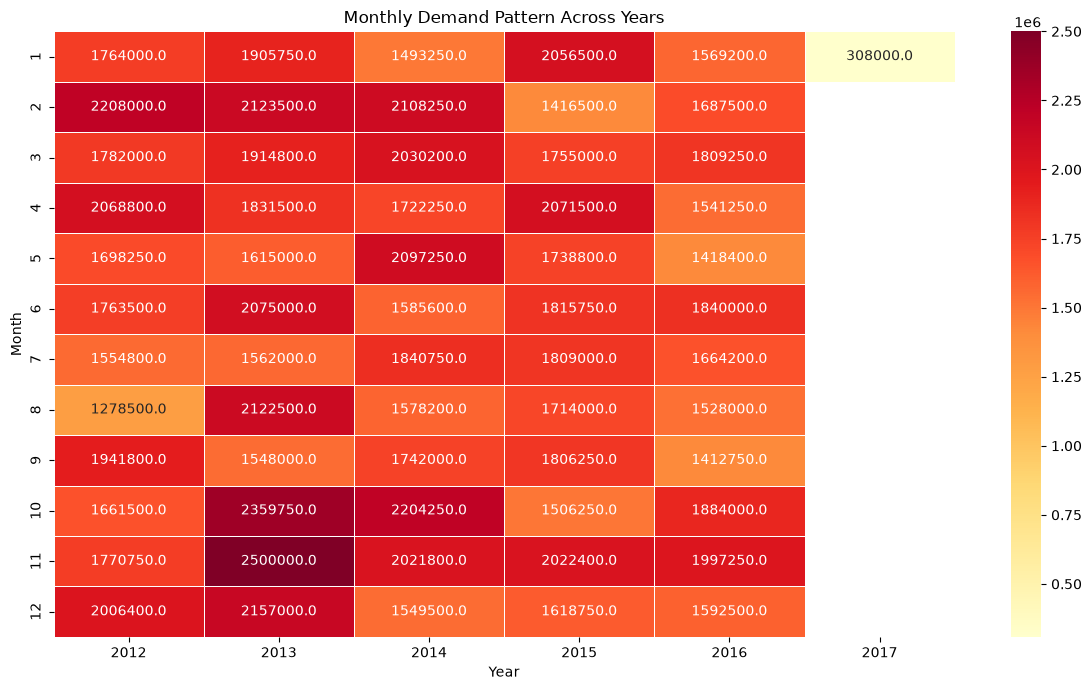

In [29]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    monthly_yearly_demand,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Monthly Demand Pattern Across Years")
plt.xlabel("Year")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

Interpretation
- 2013: February, October and November show relatively high demand.
- 2014: February, March and October are relatively high.
- 2015: January and April show higher demand, while October is lower.
- 2016: Demand is comparatively moderate, with no strong recurring peak month.
- 2017: Only January has data, so it is insufficient for seasonal comparison.

### Monthly Seasonality Analysis

The monthly demand heatmap was used to compare demand patterns across individual years.

Key findings:

- Monthly demand varies considerably between years.
- November shows relatively high demand in several years, but this pattern is not consistent across the entire period.
- Other months, including February and October, also show high demand in certain years.
- No strong, consistent annual seasonal pattern was identified.
- The 2017 observation is incomplete and was excluded from meaningful year-to-year seasonal interpretation.

**Business implication:** Inventory planning for Product_1359 should not rely solely on fixed seasonal assumptions. Historical demand levels and short-term demand variability should also be considered.

*Note: This is a descriptive analysis and does not establish the absence of all seasonal effects.*

In [30]:
# Calculate weekly demand distribution statistics

demand_stats = selected_product["Order_Demand"].describe()

print("Weekly Demand Distribution Statistics:")
display(demand_stats.to_frame(name="Weekly Demand").round(2))

print(
    "\nSkewness:",
    round(selected_product["Order_Demand"].skew(), 2)
)

print(
    "Median:",
    selected_product["Order_Demand"].median()
)

print(
    "Mean:",
    selected_product["Order_Demand"].mean()
)

Weekly Demand Distribution Statistics:


,Weekly Demand
count,262.00
mean,1796603.05
std,699788.35
min,0.00
25%,1360750.00
50%,1745000.00
75%,2166750.00
max,3703000.00



Skewness: 0.22
Median: 1745000.0
Mean: 1796603.0534351144


Key findings:
1. Mean is slightly higher than median, suggesting a mild influence from higher-demand weeks.
2. Standard deviation is approximately 700,000, indicating substantial weekly variability.
3. Skewness of 0.22 suggests the distribution is relatively close to symmetric, with a slight right tail.
4. The maximum demand is more than twice the median.
Business insight: Although the average weekly demand is around 1.8 million units, using this average alone may not adequately account for fluctuations in weekly demand.

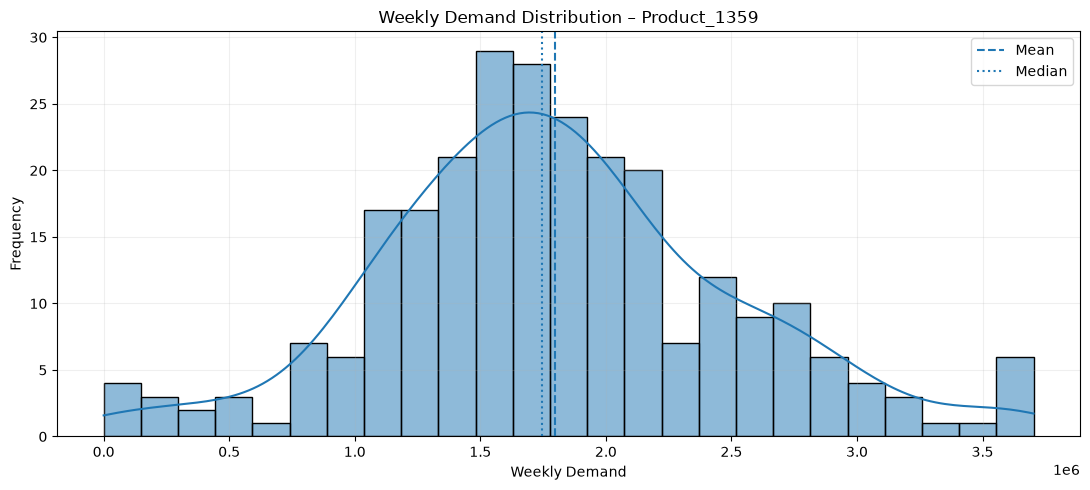

In [31]:
plt.figure(figsize=(11, 5))

sns.histplot(
    selected_product["Order_Demand"],
    bins=25,
    kde=True
)

plt.axvline(
    selected_product["Order_Demand"].mean(),
    linestyle="--",
    label="Mean"
)

plt.axvline(
    selected_product["Order_Demand"].median(),
    linestyle=":",
    label="Median"
)

plt.title("Weekly Demand Distribution – Product_1359")
plt.xlabel("Weekly Demand")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [32]:
# Identify potential demand outliers using IQR

Q1 = selected_product["Order_Demand"].quantile(0.25)
Q3 = selected_product["Order_Demand"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

potential_outliers = selected_product[
    (selected_product["Order_Demand"] < lower_bound) |
    (selected_product["Order_Demand"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Potential Outlier Weeks:", len(potential_outliers))

display(
    potential_outliers[
        ["Date", "Order_Demand"]
    ].sort_values("Order_Demand", ascending=False).head(15)
)

Q1: 1360750.0
Q3: 2166750.0
IQR: 806000.0
Lower Bound: 151750.0
Upper Bound: 3375750.0
Potential Outlier Weeks: 11


,Date,Order_Demand
425538,2013-02-03,3703000
425640,2015-01-18,3633000
425664,2015-07-05,3626000
425591,2014-02-09,3589000
425684,2015-11-22,3579000
425536,2013-01-20,3569000
425574,2013-10-13,3532000
425743,2017-01-08,100000
425534,2013-01-06,0
425638,2015-01-04,0


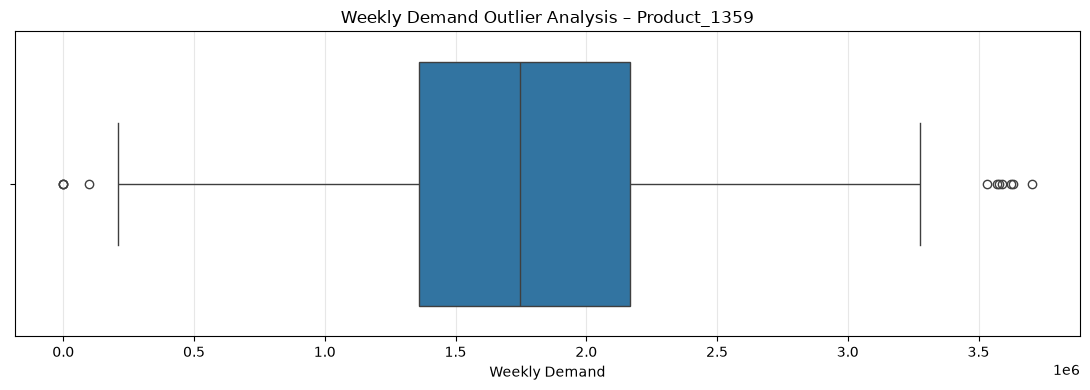

In [33]:
plt.figure(figsize=(11, 4))

sns.boxplot(
    x=selected_product["Order_Demand"]
)

plt.title("Weekly Demand Outlier Analysis – Product_1359")
plt.xlabel("Weekly Demand")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
# Compare original demand with demand excluding IQR outliers

cleaned_demand = selected_product[
    (selected_product["Order_Demand"] >= lower_bound) &
    (selected_product["Order_Demand"] <= upper_bound)
]["Order_Demand"]

comparison = pd.DataFrame({
    "Original Demand": [
        selected_product["Order_Demand"].mean(),
        selected_product["Order_Demand"].median(),
        selected_product["Order_Demand"].std()
    ],
    "Excluding Potential Outliers": [
        cleaned_demand.mean(),
        cleaned_demand.median(),
        cleaned_demand.std()
    ]
}, index=["Mean", "Median", "Standard Deviation"])

display(comparison.round(2))

,Original Demand,Excluding Potential Outliers
Mean,1796603.05,1774418.33
Median,1745000.00,1736000.00
Standard Deviation,699788.35,607392.19


### Impact of Potential Outliers on Demand Statistics

The IQR method identified 11 potential outlier weeks out of 262 observations.

A comparison was conducted between the original demand data and the data excluding these observations.

Key findings:

- Mean weekly demand decreased slightly from 1,796,603 to 1,774,418.
- Median weekly demand changed from 1,745,000 to 1,736,000.
- Standard deviation decreased from 699,788 to 607,392.
- Potential outliers have a greater influence on demand variability than on the average demand level.

**Business implication:** Unusual demand observations should not be automatically removed because they may represent genuine demand spikes or operational events. The original dataset is retained for the primary analysis.

*Note: IQR identifies statistical outliers, not confirmed data errors.*

In [35]:
# Create inventory demand classification

inventory_priority = positive_variability.copy()

inventory_priority["Demand_Frequency"] = pd.cut(
    inventory_priority["Positive_Week_Rate"],
    bins=[-np.inf, 30, 70, np.inf],
    labels=["Intermittent", "Occasional", "Frequent"],
    right=False
)

inventory_priority["Demand_Variability"] = np.where(
    inventory_priority["Positive_Demand_CV"] > 1,
    "High Variability",
    "Lower Variability"
)

# Summarise product counts by classification
priority_summary = (
    inventory_priority
    .groupby(
        ["Demand_Frequency", "Demand_Variability"],
        observed=False
    )
    .size()
    .reset_index(name="Product_Warehouse_Count")
)

display(priority_summary)

,Demand_Frequency,Demand_Variability,Product_Warehouse_Count
0,Intermittent,High Variability,486
1,Intermittent,Lower Variability,296
2,Occasional,High Variability,958
3,Occasional,Lower Variability,409
4,Frequent,High Variability,381
5,Frequent,Lower Variability,319


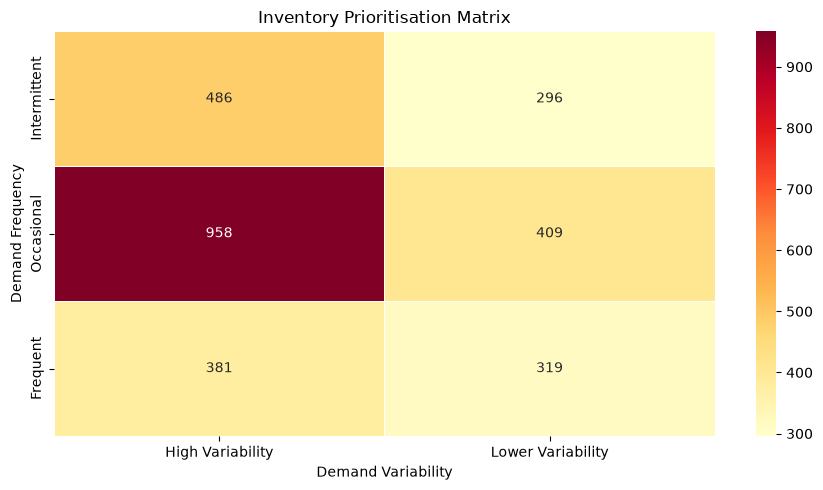

In [36]:
priority_matrix = priority_summary.pivot(
    index="Demand_Frequency",
    columns="Demand_Variability",
    values="Product_Warehouse_Count"
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    priority_matrix,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Inventory Prioritisation Matrix")
plt.xlabel("Demand Variability")
plt.ylabel("Demand Frequency")

plt.tight_layout()
plt.show()

In [37]:
# Identify products with occasional and highly variable demand

occasional_high_variability = inventory_priority[
    (inventory_priority["Demand_Frequency"] == "Occasional") &
    (inventory_priority["Demand_Variability"] == "High Variability")
].copy()

occasional_high_variability = occasional_high_variability.sort_values(
    "Positive_Demand_CV",
    ascending=False
)

print("Total products in this category:",
      len(occasional_high_variability))

display(
    occasional_high_variability[
        [
            "Average_Positive_Demand",
            "Positive_Weeks",
            "Positive_Demand_CV",
            "Positive_Week_Rate",
            "Zero_Weeks"
        ]
    ].head(10).round(2)
)

Total products in this category: 958


,,Average_Positive_Demand,Positive_Weeks,Positive_Demand_CV,Positive_Week_Rate,Zero_Weeks
Product_Code,Warehouse,,,,,
Product_0493,Whse_J,58.57,136,8.81,52.71,121
Product_0987,Whse_A,2580.66,137,7.96,51.89,125
Product_0150,Whse_J,20.27,114,6.93,44.19,144
Product_0222,Whse_J,181.88,147,5.50,57.20,109
Product_0558,Whse_S,15389.34,122,5.11,46.74,138
Product_2144,Whse_J,143.96,118,4.99,44.70,144
Product_0544,Whse_J,38.34,97,4.69,38.34,156
Product_0210,Whse_A,191.03,97,4.30,38.19,156
Product_1942,Whse_C,30.33,110,4.27,43.14,145


In [38]:
# Count occasional high-variability products by warehouse

warehouse_priority = (
    occasional_high_variability
    .groupby("Warehouse")
    .agg(
        Product_Count=("Positive_Demand_CV", "count"),
        Average_CV=("Positive_Demand_CV", "mean"),
        Average_Positive_Demand=("Average_Positive_Demand", "mean")
    )
    .sort_values("Product_Count", ascending=False)
)

display(warehouse_priority.round(2))

,Product_Count,Average_CV,Average_Positive_Demand
Warehouse,,,
Whse_J,491,1.59,2317.02
Whse_S,225,1.48,6261.77
Whse_A,164,1.57,822.83
Whse_C,78,1.52,10270.31


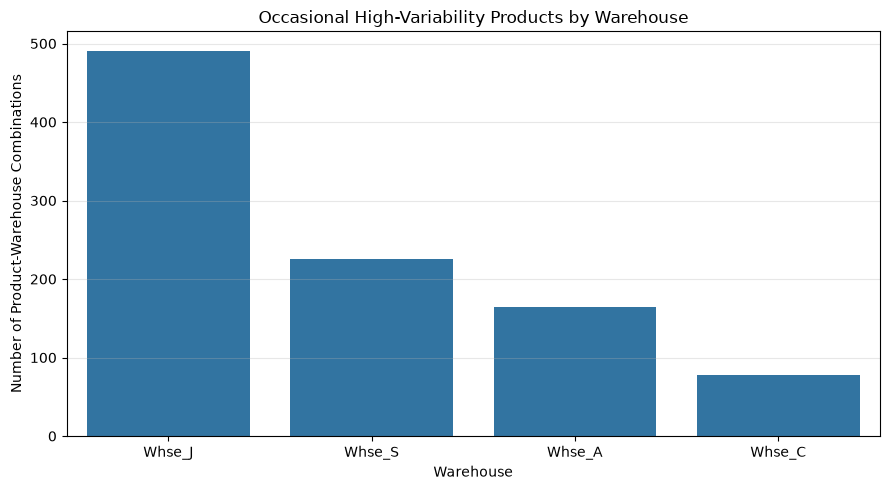

In [39]:
# Compare product counts across warehouses

plt.figure(figsize=(9, 5))

sns.barplot(
    data=warehouse_priority.reset_index(),
    x="Warehouse",
    y="Product_Count"
)

plt.title("Occasional High-Variability Products by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Number of Product-Warehouse Combinations")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [40]:
# Create warehouse-level inventory planning summary

warehouse_summary = warehouse_priority.copy()

warehouse_summary["Share_of_Category_%"] = (
    warehouse_summary["Product_Count"] /
    warehouse_summary["Product_Count"].sum() * 100
)

warehouse_summary["Suggested_Focus"] = [
    "Broad product-level review",
    "Review higher demand quantities",
    "Monitor lower-volume products",
    "Review high positive-demand quantities"
]

display(warehouse_summary.round(2))

,Product_Count,Average_CV,Average_Positive_Demand,Share_of_Category_%,Suggested_Focus
Warehouse,,,,,
Whse_J,491,1.59,2317.02,51.25,Broad product-level review
Whse_S,225,1.48,6261.77,23.49,Review higher demand quantities
Whse_A,164,1.57,822.83,17.12,Monitor lower-volume products
Whse_C,78,1.52,10270.31,8.14,Review high positive-demand quantities


Key business findings:
1. Whse_J has the largest concentration of products requiring closer demand monitoring.
2. Whse_S has the second-largest number of combinations.
3. Whse_C has fewer combinations, but its average positive demand is the highest at 10,270.31.
4. Whse_A has the lowest average positive demand at 822.83.


## Executive Summary: Inventory Planning Intelligence

### Business Objective

The objective of this analysis was to investigate historical product demand patterns and identify opportunities for more informed inventory planning across four warehouses.

### Key Findings

**1. Warehouse Demand Distribution**
- Whse_J contributed approximately 65.6% of total recorded net demand.
- Whse_S contributed approximately 20.3%.
- Whse_C contributed approximately 11.4%.
- Whse_A contributed approximately 2.8%.

**2. Product Demand Variability**
- Products displayed different demand frequencies and variability levels.
- The largest classification group was occasional demand with high variability, containing 958 product–warehouse combinations.
- Another 486 combinations showed intermittent demand with high variability.

**3. Demand Trends**
- Product_1359 at Whse_J showed frequent but highly fluctuating weekly demand.
- Its 12-week rolling average generally remained between approximately 1.5 million and 2.1 million units.
- No strong, consistent annual seasonal pattern was identified.

**4. Potential Outliers**
- The IQR method identified 11 potential outlier weeks for Product_1359.
- Removing these observations reduced standard deviation from approximately 699,788 to 607,392.
- The original observations were retained because statistical outliers are not necessarily data errors.

**5. Warehouse Inventory Prioritisation**
- Whse_J accounted for 51.25% of occasional-demand, high-variability combinations.
- Whse_S accounted for 23.49%.
- Whse_A accounted for 17.12%.
- Whse_C accounted for 8.14%.

### Business Recommendations

1. Prioritise detailed product-level demand reviews at Whse_J because it contains the largest number of occasional, high-variability combinations.
2. Consider regular replenishment planning for products with frequent and comparatively consistent demand.
3. Monitor products with highly intermittent demand rather than relying exclusively on simple average-based replenishment.
4. Investigate unusual demand spikes and low-demand periods before making inventory decisions.
5. Incorporate supplier lead times, current inventory levels, ordering costs and service-level requirements before determining actual replenishment quantities.

### Conclusion

The analysis demonstrates that demand patterns differ considerably across products and warehouses. A single inventory planning strategy may not be appropriate for every product.

Segmenting products according to demand frequency and variability provides a useful starting point for prioritising inventory reviews and developing more informed replenishment strategies.

### Limitations

- Historical transaction demand does not necessarily represent actual customer demand when products may have been unavailable.
- Zero-demand weeks indicate no recorded transactions, not confirmed absence of demand.
- Negative demand values may represent returns or adjustments; their exact meaning is not established.
- The dataset does not provide supplier lead times, inventory balances, stockout records, ordering costs or service-level targets.
- The analysis identifies descriptive demand patterns and does not establish optimal inventory quantities or prove reductions in stockouts or inventory costs.